In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
train_df = pd.read_csv("../data/processed/train_data.csv")
test_df = pd.read_csv("../data/processed/test_data.csv")

train_df["date"] = pd.to_datetime(train_df["date"])
test_df["date"] = pd.to_datetime(test_df["date"])

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

Training data: (1464, 7)
Testing data: (367, 7)


In [4]:
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")

# Start with training consumption data
arima_history = train_df["daily_consumption"].tolist()

arima_predictions = []

# Forecast in blocks of 7 days
for start in range(0, len(test_df), 7):

    end = min(start + 7, len(test_df))

    # Train ARIMA using available history
    model = ARIMA(
        arima_history,
        order=(1, 1, 1)
    )

    fitted_model = model.fit()

    # Forecast the next 7 days
    forecast = fitted_model.forecast(
        steps=end - start
    )

    arima_predictions.extend(forecast)

    # Add actual test values after completing this block
    arima_history.extend(
        test_df["daily_consumption"].iloc[start:end].tolist()
    )

arima_predictions = np.array(arima_predictions)

print("Total ARIMA predictions:", len(arima_predictions))
print("First 5 predictions:", arima_predictions[:5])

Total ARIMA predictions: 367
First 5 predictions: [52636.53700035 52820.19168172 52923.80215289 52982.25494949
 53015.23163025]


In [5]:
actual = test_df["daily_consumption"].values

arima_mae = mean_absolute_error(
    actual, arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(actual, arima_predictions)
)

arima_mape = np.mean(
    np.abs((actual - arima_predictions) / actual)
) * 100

print("ARIMA Model Performance")
print("-----------------------")
print("MAE:", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

ARIMA Model Performance
-----------------------
MAE: 5596.504647911423
RMSE: 8073.438402998507
MAPE: 8.789512571087764 %


In [7]:
xgb_metrics = pd.read_csv(
    "../results/metrics/xgboost_metrics.csv"
)

lstm_metrics = pd.read_csv(
    "../results/metrics/lstm_metrics.csv"
)

print("XGBoost Metrics:")
display(xgb_metrics)

print("LSTM Metrics:")
display(lstm_metrics)

XGBoost Metrics:


,Model,MAE,RMSE,MAPE (%)
0,XGBoost,5355.850586,8213.501081,7.986466


LSTM Metrics:


,Model,MAE,RMSE,MAPE (%)
0,LSTM,5753.522949,8585.894479,8.679965


In [8]:
comparison = pd.DataFrame({
    "Model": ["ARIMA", "XGBoost", "LSTM"],

    "MAE": [
        arima_mae,
        xgb_metrics["MAE"].iloc[0],
        lstm_metrics["MAE"].iloc[0]
    ],

    "RMSE": [
        arima_rmse,
        xgb_metrics["RMSE"].iloc[0],
        lstm_metrics["RMSE"].iloc[0]
    ],

    "MAPE (%)": [
        arima_mape,
        xgb_metrics["MAPE (%)"].iloc[0],
        lstm_metrics["MAPE (%)"].iloc[0]
    ]
})

comparison = comparison.round(2)

display(comparison)

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,5596.50,8073.44,8.79
1,XGBoost,5355.85,8213.50,7.99
2,LSTM,5753.52,8585.89,8.68


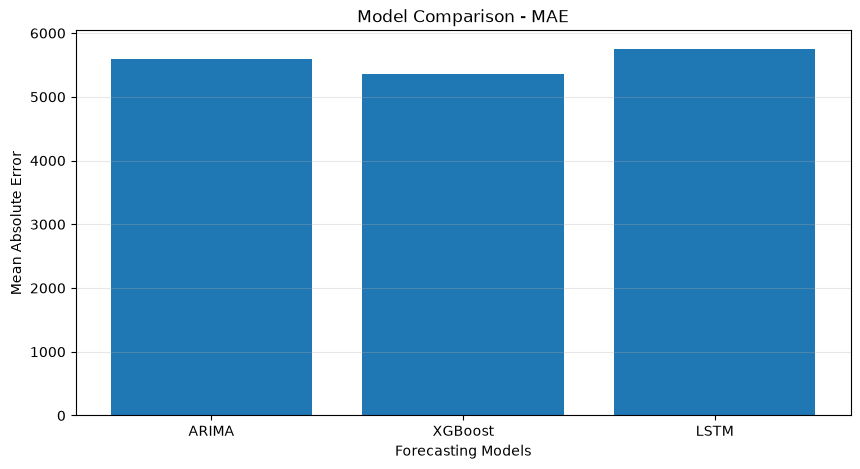

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Forecasting Models")
plt.ylabel("Mean Absolute Error")
plt.grid(axis="y", alpha=0.3)

plt.show()

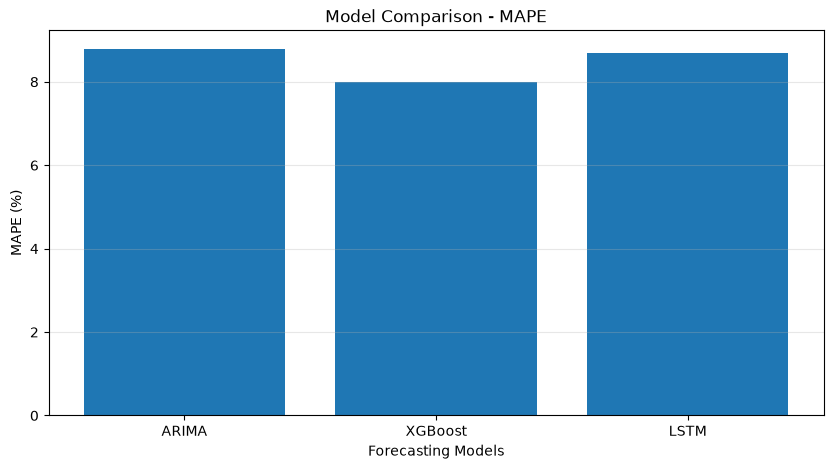

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Model"],
    comparison["MAPE (%)"]
)

plt.title("Model Comparison - MAPE")
plt.xlabel("Forecasting Models")
plt.ylabel("MAPE (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
comparison.to_csv(
    "../results/metrics/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


: 